# Multi-Class Benchmark Classification Pipeline

## Objective
Build and compare Logistic Regression and Decision Tree
classifiers using the Iris dataset.

## Tools
- Python
- Pandas and NumPy
- Scikit-Learn
- Seaborn and Matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [5]:
# Display the first five rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
# Check data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [7]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [8]:
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Exploratory Data Analysis (EDA)

We examine the Iris dataset to understand feature
distributions and relationships between flower species.

The pairplot helps us identify patterns in sepal
and petal measurements.

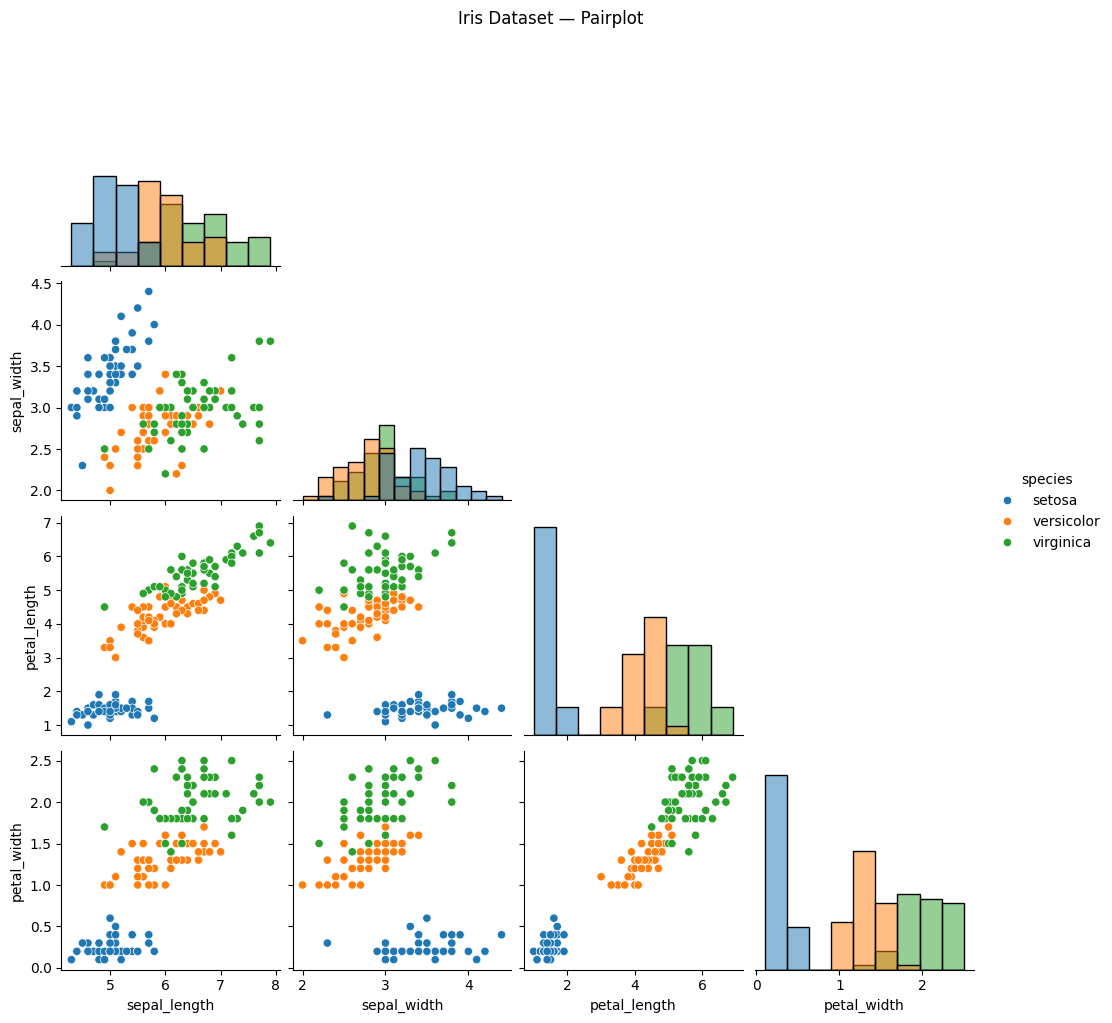

In [9]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist",
    corner=True
)

plt.suptitle("Iris Dataset — Pairplot", y=1.02)
plt.show()

In [10]:
# Features: measurements used to make predictions
X = df.drop("species", axis=1)

# Target: the species we want to predict
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training targets: (120,)
Testing targets: (30,)


In [12]:
print("Training species counts:")
print(y_train.value_counts())

print("\nTesting species counts:")
print(y_test.value_counts())

Training species counts:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing species counts:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## Model Training

We split the data into 80% training and 20% testing.

StandardScaler is fitted on the training data through
a Scikit-Learn Pipeline. We train Logistic Regression
and Decision Tree classifiers.

In [20]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [21]:
tree_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

print("Decision Tree pipeline created!")

Decision Tree pipeline created!


In [22]:
# Train Logistic Regression
logistic_model.fit(X_train, y_train)

# Train Decision Tree
tree_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [23]:
scaler = logistic_model.named_steps["scaler"]

print("Training feature means:")
print(scaler.mean_)

print("\nTraining feature standard deviations:")
print(scaler.scale_)

Training feature means:
[5.84166667 3.04833333 3.77       1.205     ]

Training feature standard deviations:
[0.837415   0.44665112 1.761136   0.75947899]


In [24]:
X_train_scaled = scaler.transform(X_train)

print("Scaled training means:")
print(X_train_scaled.mean(axis=0).round(3))

print("\nScaled training standard deviations:")
print(X_train_scaled.std(axis=0).round(3))

Scaled training means:
[-0.  0.  0.  0.]

Scaled training standard deviations:
[1. 1. 1. 1.]


In [25]:
# Predict the species using both trained models
y_pred_logistic = logistic_model.predict(X_test)
y_pred_tree = tree_model.predict(X_test)

print("Logistic Regression predictions:")
print(y_pred_logistic)

print("\nDecision Tree predictions:")
print(y_pred_tree)

Logistic Regression predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Decision Tree predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


## Model Evaluation

We compare accuracy, precision, recall, and F1-score
using the test dataset.

Classification reports and confusion matrices help
us examine the performance of each model.

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Logistic Regression metrics
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(
    y_test, y_pred_logistic, average="weighted"
)
logistic_recall = recall_score(
    y_test, y_pred_logistic, average="weighted"
)
logistic_f1 = f1_score(
    y_test, y_pred_logistic, average="weighted"
)

# Decision Tree metrics
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(
    y_test, y_pred_tree, average="weighted"
)
tree_recall = recall_score(
    y_test, y_pred_tree, average="weighted"
)
tree_f1 = f1_score(
    y_test, y_pred_tree, average="weighted"
)

print("Logistic Regression")
print("Accuracy:", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1-score:", round(logistic_f1, 4))

print("\nDecision Tree")
print("Accuracy:", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1-score:", round(tree_f1, 4))

Logistic Regression
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333

Decision Tree
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333


In [27]:
print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, y_pred_logistic))

print("\nDECISION TREE REPORT")
print(classification_report(y_test, y_pred_tree))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


DECISION TREE REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [28]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [logistic_accuracy, tree_accuracy],
    "Precision": [logistic_precision, tree_precision],
    "Recall": [logistic_recall, tree_recall],
    "F1-score": [logistic_f1, tree_f1]
})

results = results.set_index("Model")

results.round(4)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


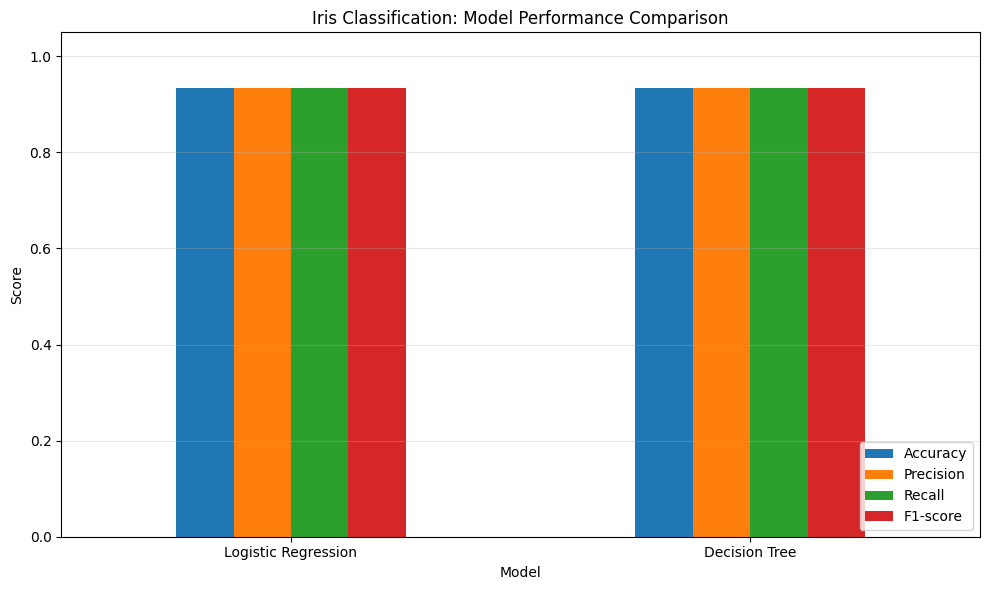

In [29]:
results.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05),
    rot=0
)

plt.title("Iris Classification: Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

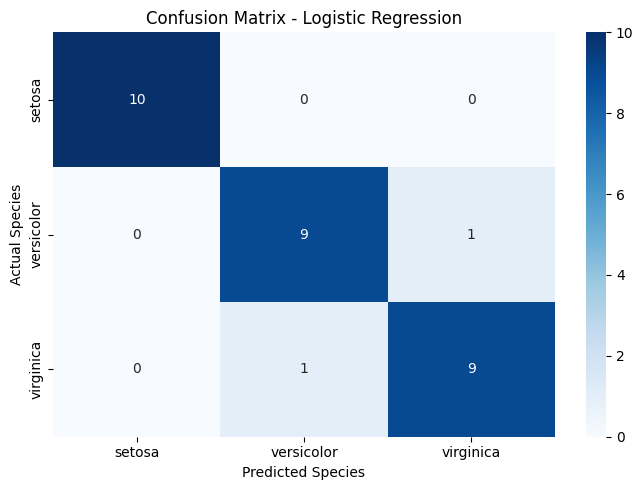

In [30]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=logistic_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

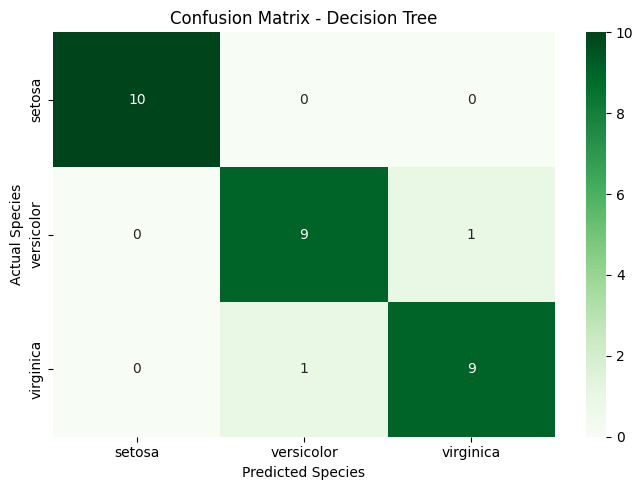

In [31]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=tree_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=tree_model.classes_,
    yticklabels=tree_model.classes_
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

In [32]:
# Select two features for visualization
X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]

# Split into training and testing sets
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

print("2D training shape:", X_train_2d.shape)
print("2D testing shape:", X_test_2d.shape)

2D training shape: (120, 2)
2D testing shape: (30, 2)


In [33]:
# Logistic Regression using two features
logistic_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Decision Tree using two features
tree_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

logistic_2d.fit(X_train_2d, y_train_2d)
tree_2d.fit(X_train_2d, y_train_2d)

print("Both 2D visualization models trained!")

Both 2D visualization models trained!


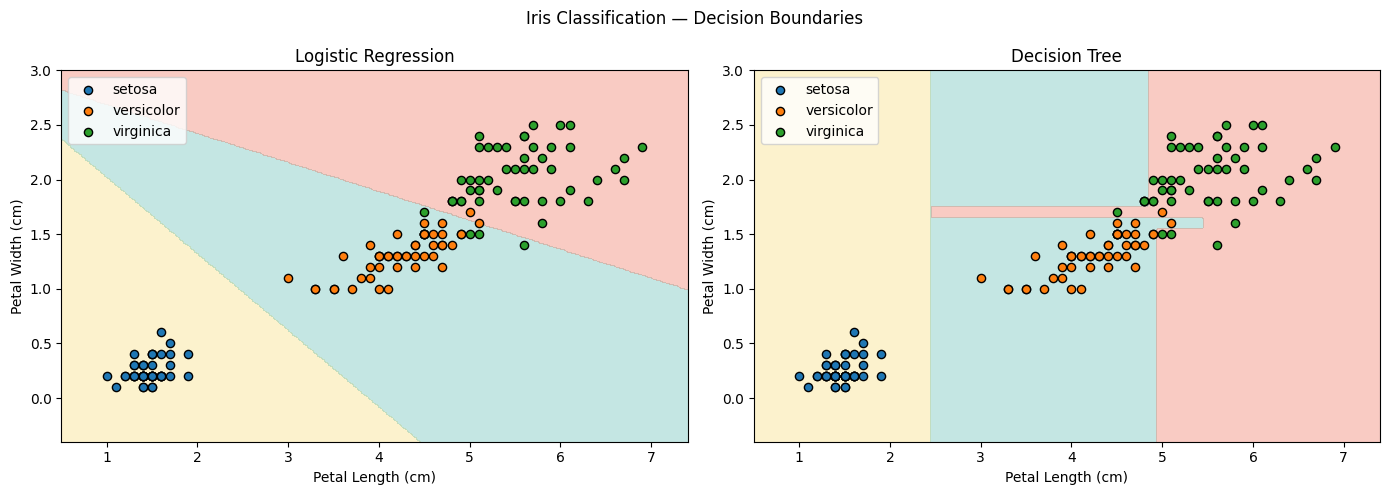

In [34]:
from matplotlib.colors import ListedColormap

# Create a grid of petal measurements
x_min = X_2d["petal_length"].min() - 0.5
x_max = X_2d["petal_length"].max() + 0.5
y_min = X_2d["petal_width"].min() - 0.5
y_max = X_2d["petal_width"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "petal_length": xx.ravel(),
    "petal_width": yy.ravel()
})

# Map species to numeric codes for plotting
species_to_num = {
    species: i for i, species
    in enumerate(logistic_2d.classes_)
}

colors = ["#F6D55C", "#3CAEA3", "#ED553B"]
cmap = ListedColormap(colors)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (logistic_2d, "Logistic Regression"),
    (tree_2d, "Decision Tree")
]

for ax, (model, title) in zip(axes, models):
    predictions = model.predict(grid)
    Z = np.array([species_to_num[s] for s in predictions])
    Z = Z.reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap=cmap,
        levels=np.arange(-0.5, 3.5, 1)
    )

    for species in model.classes_:
        mask = y_2d == species
        ax.scatter(
            X_2d.loc[mask, "petal_length"],
            X_2d.loc[mask, "petal_width"],
            label=species,
            edgecolor="black",
            s=35
        )

    ax.set_title(title)
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.legend()

plt.suptitle("Iris Classification — Decision Boundaries")
plt.tight_layout()
plt.show()

In [35]:
final_results = results.reset_index().copy()

final_results[
    ["Accuracy", "Precision", "Recall", "F1-score"]
] = final_results[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].round(4)

final_results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


## Conclusion

Both classifiers achieved 93.33% accuracy on the test
set in this experiment.

We compared their performance using multiple metrics
and visualized their predictions with confusion matrices
and decision boundaries.

These results apply to this particular train/test split.